# Final Examination: AI and Big Data Analytics
## Variant B: Bike Sharing (UCI), hourly rentals

**Student:** Aktan Seraliyev
**ID and group:** 255522, DBAIT-2501
**Data:** UCI Bike Sharing Dataset, `hour.csv` (Capital Bikeshare, Washington D.C., 2011 to 2012)
**Random seed:** 42

Run all cells from top to bottom. The notebook reads `data/hour.csv` and writes `data/hour_clean.csv`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA = Path('data/hour.csv')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

def reg_metrics(name, part, y, p):
    return {'model': name, 'partition': part, 'n': len(y),
            'MAE': mean_absolute_error(y, p),
            'RMSE': np.sqrt(mean_squared_error(y, p)),
            'R2': r2_score(y, p)}
print('Ready. Seed =', RANDOM_STATE)

Ready. Seed = 42


# Part 1. Framing and data audit

**Primary question.** How accurately can hourly bike demand be predicted one day ahead from calendar, weather and past demand, compared with a simple same-hour-last-week rule?

**Supporting questions.**
1. How do demand patterns differ by hour, working-day status, season and weather?
2. Can days be grouped by their weather into types that call for different operating plans?

**Units of analysis.** Raw row = one hour (Part 1 to 4). Modelling table = one hour with lag features built on a complete hourly grid. Statistical tests, clustering and the time series use one day (hours summed or averaged).

In [2]:
if not DATA.exists():
    from google.colab import files   # Colab fallback
    up = files.upload(); DATA.parent.mkdir(exist_ok=True); Path(next(iter(up))).rename(DATA)

raw = pd.read_csv(DATA)
print('Original shape:', raw.shape)
display(raw.dtypes.to_frame('dtype').T)
raw['dteday'] = pd.to_datetime(raw['dteday'])
print('Time coverage:', raw['dteday'].min().date(), 'to', raw['dteday'].max().date(),
      '|', raw['dteday'].nunique(), 'days')

per_day = raw.groupby('dteday').size()
audit = pd.Series({
    'Missing cells': int(raw.isna().sum().sum()),
    'Duplicate rows': int(raw.duplicated().sum()),
    'Duplicate date-hour pairs': int(raw.duplicated(['dteday', 'hr']).sum()),
    'Expected hours (731 x 24)': 731 * 24,
    'Absent hours': 731 * 24 - len(raw),
    'Days with fewer than 24 rows': int((per_day < 24).sum()),
    'cnt == casual + registered (all rows)': bool((raw['cnt'] == raw['casual'] + raw['registered']).all()),
    'weathersit == 4 (heavy rain/snow)': int((raw['weathersit'] == 4).sum()),
    'hum == 0 (impossible)': int((raw['hum'] == 0).sum()),
    'windspeed == 0': int((raw['windspeed'] == 0).sum()),
    'atemp more than 0.2 below temp': int(((raw['temp'] - raw['atemp']) > 0.2).sum()),
})
display(audit.to_frame('value'))
print('Days with the fewest recorded hours:')
display(per_day[per_day < 20].sort_values().to_frame('hours_recorded'))
print('Rows with hum == 0 come from:', raw.loc[raw['hum'] == 0, 'dteday'].dt.date.unique())
print('Rows with broken atemp come from:', raw.loc[(raw['temp'] - raw['atemp']) > 0.2, 'dteday'].dt.date.unique())

Original shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
dtype,int64,str,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64


Time coverage: 2011-01-01 to 2012-12-31 | 731 days


,value
Missing cells,0
Duplicate rows,0
Duplicate date-hour pairs,0
Expected hours (731 x 24),17544
Absent hours,165
Days with fewer than 24 rows,76
cnt == casual + registered (all rows),True
weathersit == 4 (heavy rain/snow),3
hum == 0 (impossible),22
windspeed == 0,2180


Days with the fewest recorded hours:


,hours_recorded
dteday,
2012-10-29,1
2011-01-27,8
2012-10-30,11
2011-01-18,12
2011-01-26,16
2011-08-28,17
2011-02-22,18
2011-08-27,18


Rows with hum == 0 come from: [datetime.date(2011, 3, 10)]
Rows with broken atemp come from: [datetime.date(2012, 8, 17)]


### Data dictionary

In [3]:
dictionary = pd.DataFrame([
    ['instant', 'int', 'Row index', 'Dropped (identifier)'],
    ['dteday', 'date', 'Calendar date', 'Time index'],
    ['season', 'cat 1-4', '1 winter, 2 spring, 3 summer, 4 autumn', 'Feature'],
    ['yr', '0/1', '0 = 2011, 1 = 2012', 'Feature (trend)'],
    ['mnth', 'cat 1-12', 'Month', 'Feature'],
    ['hr', 'cat 0-23', 'Hour of day', 'Feature'],
    ['holiday', '0/1', 'Public holiday', 'Feature'],
    ['weekday', 'cat 0-6', '0 = Sunday', 'Feature'],
    ['workingday', '0/1', 'Neither weekend nor holiday', 'Feature'],
    ['weathersit', 'cat 1-4', '1 clear, 2 mist/cloudy, 3 light rain/snow, 4 heavy rain/snow', 'Feature (4 merged into 3)'],
    ['temp', 'num 0-1', 'Temperature, Celsius / 41', 'Feature'],
    ['atemp', 'num 0-1', 'Feels-like temperature, Celsius / 50', 'Excluded (r = 0.99 with temp, broken on 2012-08-17)'],
    ['hum', 'num 0-1', 'Relative humidity / 100', 'Feature (0 set to missing)'],
    ['windspeed', 'num 0-1', 'Wind speed / 67', 'Feature + zero flag'],
    ['casual', 'count', 'Rentals by non-registered users', 'Excluded (part of target)'],
    ['registered', 'count', 'Rentals by registered users', 'Excluded (part of target)'],
    ['cnt', 'count', 'Total rentals in the hour = casual + registered', 'Target'],
    ['lag24, lag168', 'count', 'cnt same hour 1 day and 7 days earlier (engineered)', 'Feature'],
    ['hr_daytype', 'cat 0-47', 'hour + 24 x workingday (engineered)', 'Feature'],
], columns=['variable', 'type', 'meaning', 'use'])
display(dictionary)

,variable,type,meaning,use
0,instant,int,Row index,Dropped (identifier)
1,dteday,date,Calendar date,Time index
2,season,cat 1-4,"1 winter, 2 spring, 3 summer, 4 autumn",Feature
3,yr,0/1,"0 = 2011, 1 = 2012",Feature (trend)
4,mnth,cat 1-12,Month,Feature
5,hr,cat 0-23,Hour of day,Feature
6,holiday,0/1,Public holiday,Feature
7,weekday,cat 0-6,0 = Sunday,Feature
8,workingday,0/1,Neither weekend nor holiday,Feature
9,weathersit,cat 1-4,"1 clear, 2 mist/cloudy, 3 light rain/snow, 4 h...",Feature (4 merged into 3)


### Cleaning decisions

In [4]:
df = raw.copy()
log = []
n = (df['weathersit'] == 4).sum(); df.loc[df['weathersit'] == 4, 'weathersit'] = 3
log.append(['weathersit 4 merged into 3', n, 'Only 3 rows; too rare to learn'])
n = (df['hum'] == 0).sum(); df.loc[df['hum'] == 0, 'hum'] = np.nan
log.append(['hum = 0 set to missing', n, 'All on 2011-03-10; sensor fault. Imputed in pipeline (train median)'])
df['wind_zero'] = (df['windspeed'] == 0).astype(int)
log.append(['windspeed = 0 flagged', int(df['wind_zero'].sum()), 'Likely missing coded as 0; value kept, flag added'])
log.append(['atemp dropped', len(df), 'Duplicate of temp (r = 0.99); 24 broken values on 2012-08-17'])
log.append(['casual, registered, instant excluded', len(df), 'Target leakage / identifier'])

# Complete hourly grid so that lags point to the right hour; absent hours stay missing (not zero)
df['ts'] = df['dteday'] + pd.to_timedelta(df['hr'], unit='h')
grid = pd.DataFrame({'ts': pd.date_range(df['ts'].min(), df['ts'].max(), freq='h')})
full = grid.merge(df[['ts', 'cnt']], on='ts', how='left')
for L in (24, 168):
    full[f'lag{L}'] = full['cnt'].shift(L)
df = df.merge(full[['ts', 'lag24', 'lag168']], on='ts', how='left')
log.append(['lag24 missing', int(df['lag24'].isna().sum()), 'First day or absent hour; imputed / handled in pipeline'])
log.append(['lag168 missing', int(df['lag168'].isna().sum()), 'First week or absent hour; imputed / handled in pipeline'])
display(pd.DataFrame(log, columns=['decision', 'rows affected', 'reason']))

df['hr_daytype'] = df['hr'] + 24 * df['workingday']   # hour x working-day interaction (48 levels)
log.append(['hr_daytype created', len(df), 'Hour profile differs by day type (Figure 2)'])
df = df.drop(columns=['instant', 'atemp'])
df.to_csv('data/hour_clean.csv', index=False)
print('Analytical table:', df.shape, '-> data/hour_clean.csv')

,decision,rows affected,reason
0,weathersit 4 merged into 3,3,Only 3 rows; too rare to learn
1,hum = 0 set to missing,22,All on 2011-03-10; sensor fault. Imputed in pi...
2,windspeed = 0 flagged,2180,"Likely missing coded as 0; value kept, flag added"
3,atemp dropped,17379,Duplicate of temp (r = 0.99); 24 broken values...
4,"casual, registered, instant excluded",17379,Target leakage / identifier
5,lag24 missing,160,First day or absent hour; imputed / handled in...
6,lag168 missing,304,First week or absent hour; imputed / handled i...


Analytical table: (17379, 20) -> data/hour_clean.csv


**Audit summary.** The file has 17,379 rows and 17 columns, covering 731 days from 2011-01-01 to 2012-12-31. There are no empty cells and no duplicate date-hour pairs. But 165 of the 17,544 possible hours are absent, spread over 76 days. Most gaps are single night hours, which probably had zero rentals. A few are outages: 2012-10-29 has one recorded hour (Hurricane Sandy) and 2011-01-27 has eight (snow storm). I did not fill absent hours with zero. They stay missing, and lag features that point to them are imputed.

Invalid values: humidity is 0 for all 22 hours of 2011-03-10 (sensor fault, set to missing). `atemp` is stuck at 0.24 on 2012-08-17 while temp is 0.84 (24 rows); since `atemp` correlates 0.99 with `temp`, I dropped it. Wind speed is exactly 0 in 2,180 hours (12.5%), which looks like missing data coded as zero; I kept it and added a flag. Weather code 4 appears 3 times and was merged into code 3.

**Risks.** (1) The data cover one city and two years in which the system was growing fast, so the trend will not continue the same way. (2) Weather is the observed value, not a forecast. A real day-ahead model would be less accurate. (3) Absent hours and zero-wind readings are measurement problems, not real behaviour.

# Part 2. EDA and statistical evidence

In [5]:
num = ['cnt', 'temp', 'hum', 'windspeed']
d = df[num].describe().T
d['skew'] = df[num].skew()
d['IQR'] = d['75%'] - d['25%']
d['outliers_1.5IQR'] = [int((df[c] > df[c].quantile(.75) + 1.5 * (df[c].quantile(.75) - df[c].quantile(.25))).sum()) for c in num]
display(d)
for c in ['season', 'weathersit', 'workingday', 'holiday']:
    display(df.groupby(c)['cnt'].agg(['size', 'mean', 'median']).rename(columns={'size': 'hours'}))

,count,mean,std,min,25%,50%,75%,max,skew,IQR,outliers_1.5IQR
cnt,"17,379.000",189.463,181.388,1.000,40.000,142.000,281.000,977.000,1.277,241.000,505
temp,"17,379.000",0.497,0.193,0.020,0.340,0.500,0.660,1.000,-0.006,0.320,0
hum,"17,357.000",0.628,0.192,0.080,0.480,0.630,0.780,1.000,-0.082,0.300,0
windspeed,"17,379.000",0.190,0.122,0.000,0.104,0.194,0.254,0.851,0.575,0.149,342


,hours,mean,median
season,,,
1,4242,111.115,76.000
2,4409,208.344,165.000
3,4496,236.016,199.000
4,4232,198.869,155.500


,hours,mean,median
weathersit,,,
1,11413,204.869,159.000
2,4544,175.165,133.000
3,1422,111.501,63.000


,hours,mean,median
workingday,,,
0,5514,181.405,119.000
1,11865,193.208,151.000


,hours,mean,median
holiday,,,
0,16879,190.429,144.000
1,500,156.870,97.000


**Figure 1 (distribution). How is hourly demand distributed?**

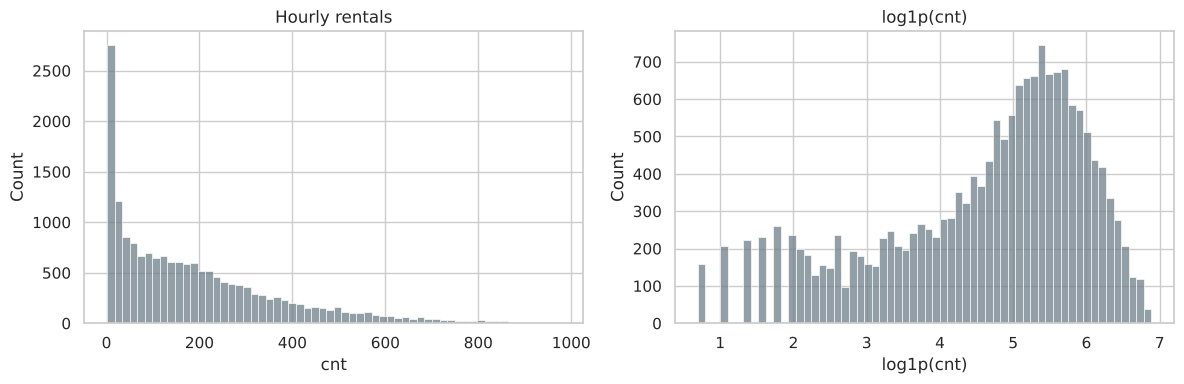

Median 142.0 | mean 189.5 | hours with cnt <= 10: 1980


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['cnt'], bins=60, ax=ax[0], color='#6F7F89'); ax[0].set(title='Hourly rentals', xlabel='cnt')
sns.histplot(np.log1p(df['cnt']), bins=60, ax=ax[1], color='#6F7F89'); ax[1].set(title='log1p(cnt)', xlabel='log1p(cnt)')
plt.tight_layout(); plt.savefig(FIG / 'f1_distribution.png', dpi=150); plt.show()
print('Median', df['cnt'].median(), '| mean', round(df['cnt'].mean(), 1), '| hours with cnt <= 10:', int((df['cnt'] <= 10).sum()))

**Finding.** Hourly demand is right-skewed (skewness 1.28). The median is 142 and the mean is 189. In 1,980 hours there were 10 rentals or fewer, while the busiest hour had 977. The 505 values above the 1.5 IQR fence are rush-hour peaks, not errors, so I kept them. Because the target is a skewed count, I used a log target for Ridge and a Poisson loss for gradient boosting.

*Limitation:* the histogram mixes night and day hours, so it hides the daily cycle.

**Figure 2 (comparison across groups). How does the daily demand curve differ between working and non-working days?**

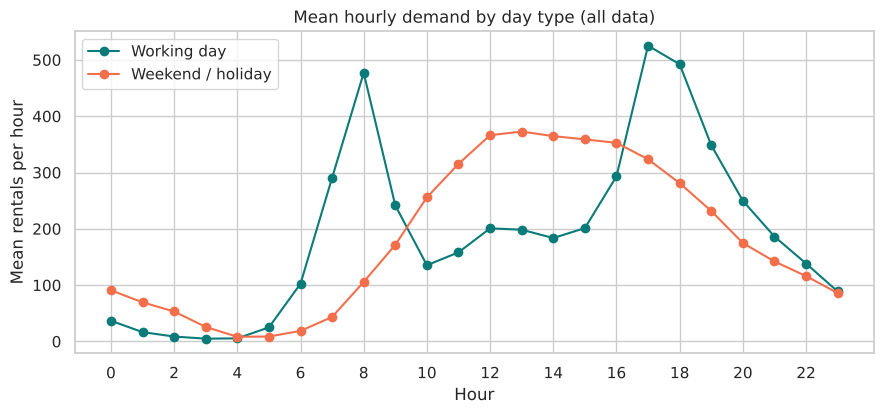

workingday,0,1
hr,,
8,106.000,477.000
13,373.000,198.000
17,324.000,525.000


In [7]:
prof = df.groupby(['workingday', 'hr'])['cnt'].mean().unstack(0)
plt.figure(figsize=(9, 4.3))
plt.plot(prof.index, prof[1], marker='o', label='Working day', color='#0A7B78')
plt.plot(prof.index, prof[0], marker='o', label='Weekend / holiday', color='#F36F4B')
plt.xticks(range(0, 24, 2)); plt.xlabel('Hour'); plt.ylabel('Mean rentals per hour'); plt.legend()
plt.title('Mean hourly demand by day type (all data)')
plt.tight_layout(); plt.savefig(FIG / 'f2_hour_profile.png', dpi=150); plt.show()
display(prof.loc[[8, 13, 17]].round(0))

**Finding.** The two day types have different shapes. On working days demand peaks at 8:00 (477 per hour) and 17:00 (525). On weekends and holidays it rises slowly to a midday plateau (373 at 13:00) and is only 106 at 8:00. Because of this, an hour-only feature is not enough. I added a combined hour-by-day-type feature.

*Limitation:* these are averages over two years, so seasonal changes in the shape are hidden.

**Figure 3 (relationship). How does demand change with temperature and weather situation?**

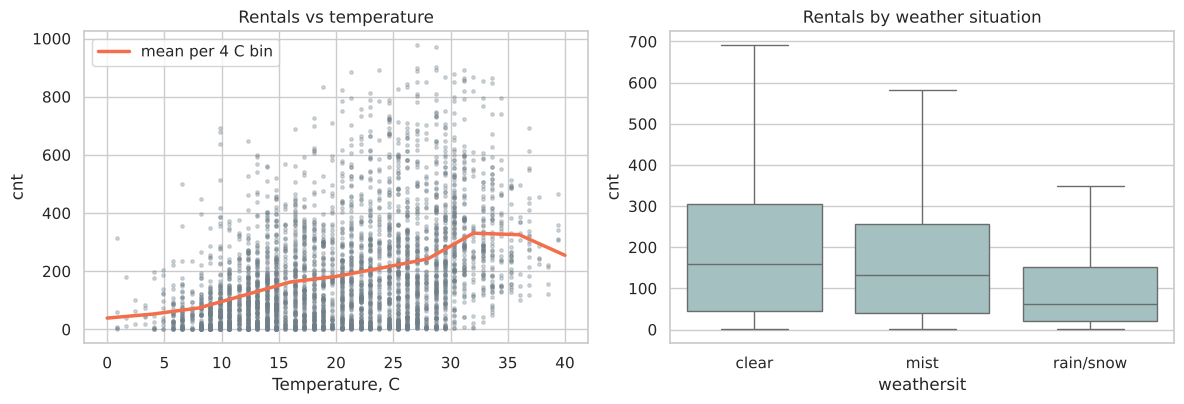

,mean cnt
temp_c,
"(-2, 2]",39.000
"(2, 6]",53.000
"(6, 10]",74.000
"(10, 14]",118.000
"(14, 18]",163.000
"(18, 22]",182.000
"(22, 26]",211.000
"(26, 30]",242.000
"(30, 34]",331.000


In [8]:
tmp = df.assign(temp_c=df['temp'] * 41)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
s = tmp.sample(4000, random_state=RANDOM_STATE)
ax[0].scatter(s['temp_c'], s['cnt'], s=6, alpha=.3, color='#6F7F89')
bins = tmp.groupby(pd.cut(tmp['temp_c'], range(-10, 45, 4)), observed=True)['cnt'].mean()
ax[0].plot([b.mid for b in bins.index], bins.values, color='#F36F4B', lw=2.5, label='mean per 4 C bin')
ax[0].set(title='Rentals vs temperature', xlabel='Temperature, C', ylabel='cnt'); ax[0].legend()
sns.boxplot(data=df, x='weathersit', y='cnt', ax=ax[1], color='#9FC5C4', showfliers=False)
ax[1].set(title='Rentals by weather situation', xticklabels=['clear', 'mist', 'rain/snow'])
plt.tight_layout(); plt.savefig(FIG / 'f3_weather.png', dpi=150); plt.show()
display(bins.round(0).to_frame('mean cnt'))

**Finding.** Demand goes up with temperature until about 30 to 34 C (331 per hour) and then drops (255 above 38 C). The relationship is not linear, which favours a tree-based model. Rain or snow hours have a median of 63 rentals, compared with 159 in clear hours.

*Limitation:* temperature and season move together, so this plot cannot separate their effects.

**Figure 4 (time). How did daily demand move over the two years?**

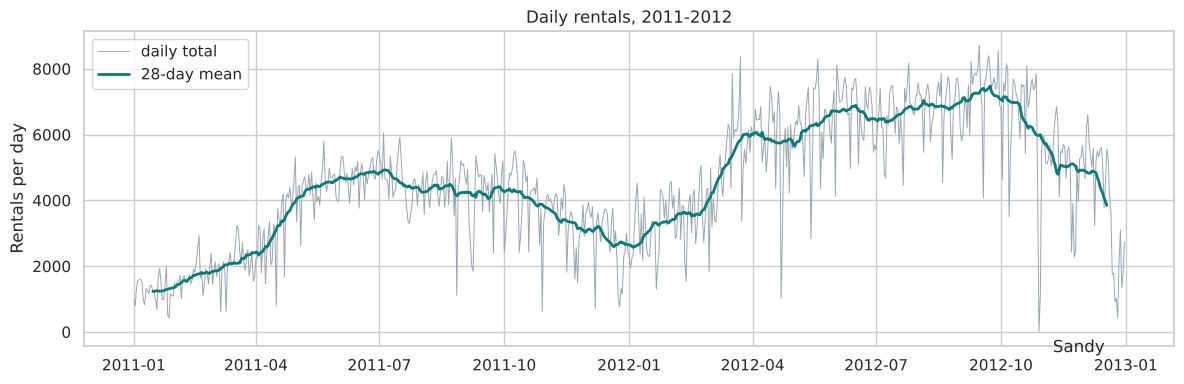

Mean daily rentals 2011: 3406 | 2012: 5600
Lowest days:


,cnt,hours,bad_hours
dteday,,,
2012-10-29,22,1,1
2011-01-27,431,8,0
2012-12-26,441,24,16
2011-01-26,506,16,14
2011-03-06,605,23,9


In [9]:
daily = df.groupby('dteday').agg(cnt=('cnt', 'sum'), temp=('temp', 'mean'), hum=('hum', 'mean'),
                                 windspeed=('windspeed', 'mean'), workingday=('workingday', 'first'),
                                 holiday=('holiday', 'first'), weekday=('weekday', 'first'),
                                 mnth=('mnth', 'first'), yr=('yr', 'first'),
                                 bad_hours=('weathersit', lambda s: int((s == 3).sum())),
                                 hours=('cnt', 'size'))
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily['cnt'], lw=.7, color='#9AA5AD', label='daily total')
plt.plot(daily.index, daily['cnt'].rolling(28, center=True).mean(), color='#0A7B78', lw=2, label='28-day mean')
for day, txt in [('2012-10-29', 'Sandy')]:
    plt.annotate(txt, (pd.Timestamp(day), daily.loc[day, 'cnt']), xytext=(10, -15), textcoords='offset points')
plt.ylabel('Rentals per day'); plt.legend(); plt.title('Daily rentals, 2011-2012')
plt.tight_layout(); plt.savefig(FIG / 'f4_daily_series.png', dpi=150); plt.show()
print('Mean daily rentals 2011:', round(daily.loc[daily['yr'] == 0, 'cnt'].mean()), '| 2012:', round(daily.loc[daily['yr'] == 1, 'cnt'].mean()))
print('Lowest days:'); display(daily.nsmallest(5, 'cnt')[['cnt', 'hours', 'bad_hours']])

**Finding.** Mean daily rentals grew from 3,406 in 2011 to 5,600 in 2012 (+64%). Both years have a summer peak and a winter low, and September 2012 is the highest month (7,286 per day). The sharpest drop is 2012-10-29, with 22 rentals during Hurricane Sandy. The strong trend means a random split would leak the future, so I used a chronological split and kept the year as a feature.

*Limitation:* two years are too few to separate long-term growth from yearly seasonality.

### Statistical tests (day level, to reduce hour-to-hour dependence)

In [10]:
daily['commute_share'] = df[df['hr'].isin([7, 8, 9, 16, 17, 18, 19])].groupby('dteday')['cnt'].sum() / daily['cnt']
full_days = daily[daily['hours'] >= 20]          # 8 days with heavy gaps (e.g. Sandy) excluded from the share test
w, nw = full_days[full_days['workingday'] == 1], full_days[full_days['workingday'] == 0]

def mw(a, b, label):
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    r = 1 - 2 * u / (len(a) * len(b))          # rank-biserial (b vs a)
    return {'test': label, 'n1': len(a), 'n2': len(b), 'median_1': a.median(), 'median_2': b.median(),
            'U': u, 'p_value': p, 'rank_biserial': -r}

rho, p_rho = stats.spearmanr(daily['temp'] * 41, daily['cnt'])
rho_y = [stats.spearmanr(daily.loc[daily['yr'] == y, 'temp'], daily.loc[daily['yr'] == y, 'cnt'])[0] for y in (0, 1)]
tests = pd.DataFrame([
    mw(w['commute_share'], nw['commute_share'], 'T1: commute-hour share, working vs non-working days'),
    mw(daily.loc[daily['workingday'] == 1, 'cnt'], daily.loc[daily['workingday'] == 0, 'cnt'], 'T1b: daily total, working vs non-working days (all 731 days)'),
])
display(tests)
print(f'T2: Spearman rho(daily mean temperature, daily rentals) = {rho:.3f}, p = {p_rho:.2e}, n = {len(daily)}')
print(f'    within 2011: rho = {rho_y[0]:.3f}; within 2012: rho = {rho_y[1]:.3f}')
print(f'Shapiro-Wilk on daily cnt: p = {stats.shapiro(daily["cnt"]).pvalue:.2e} (normality rejected -> rank-based tests)')

,test,n1,n2,median_1,median_2,U,p_value,rank_biserial
0,"T1: commute-hour share, working vs non-working...",494,229,0.586,0.345,"112,453.000",0.000,0.988
1,"T1b: daily total, working vs non-working days ...",500,231,"4,582.000","4,459.000","61,893.000",0.119,0.072


T2: Spearman rho(daily mean temperature, daily rentals) = 0.622, p = 1.68e-79, n = 731
    within 2011: rho = 0.762; within 2012: rho = 0.700
Shapiro-Wilk on daily cnt: p = 2.08e-08 (normality rejected -> rank-based tests)


**Test 1 (Mann-Whitney U).** Daily data are not normal (Shapiro-Wilk p < 0.001), so I used a rank test. On working days a median of 58.6% of rentals happen in commute hours (7-9, 16-19). On non-working days the figure is 34.5% (n = 494 vs 229 days with at least 20 recorded hours; U = 112,453; p < 0.001; rank-biserial r = 0.99). The effect is very large. The daily *total*, on the other hand, barely differs: 4,582 vs 4,459 (p = 0.12, r = 0.07). So working days change *when* people ride, not *how much*.

**Test 2 (Spearman).** Daily mean temperature and daily rentals: rho = 0.62 (p < 0.001, n = 731). Within each year it is even higher (0.76 in 2011, 0.70 in 2012), because the 2012 growth hides part of the link. This is an association. Season, daylight and tourism all move with temperature.

**Caution.** Consecutive days are not independent, so the p-values are too optimistic. Effect sizes matter more here.

**Three findings that shaped the modelling.**
1. The hour profile depends on day type, so I built `hr_daytype`.
2. The target is a skewed count with a non-linear temperature effect, so I used a log or Poisson target and a tree model.
3. There is strong growth and seasonality, so I used a chronological split with lags of 24 and 168 hours.

# Part 3. Preprocessing and PCA

**Split (fixed before any fitting).** Train: 2011-01-01 to 2012-06-30. Validation: 2012-07-01 to 2012-09-30. Test: 2012-10-01 to 2012-12-31. The test quarter is used once, at the end.

In [11]:
train = df[df['dteday'] < '2012-07-01'].copy()
val = df[(df['dteday'] >= '2012-07-01') & (df['dteday'] < '2012-10-01')].copy()
test = df[df['dteday'] >= '2012-10-01'].copy()
dev = pd.concat([train, val])
display(pd.DataFrame({'rows': [len(train), len(val), len(test)],
                      'from': [train['dteday'].min().date(), val['dteday'].min().date(), test['dteday'].min().date()],
                      'to': [train['dteday'].max().date(), val['dteday'].max().date(), test['dteday'].max().date()],
                      'mean_cnt': [train['cnt'].mean(), val['cnt'].mean(), test['cnt'].mean()]},
                     index=['train', 'validation', 'test']))

CAT = ['hr_daytype', 'hr', 'weekday', 'mnth', 'season', 'weathersit']
NUM = ['temp', 'hum', 'windspeed']
LAG = ['lag24', 'lag168']
BIN = ['yr', 'holiday', 'workingday', 'wind_zero']
FEATURES = CAT + NUM + LAG + BIN

def linear_prep():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
        ('lag', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p)), ('sc', StandardScaler())]), LAG),
        ('bin', 'passthrough', BIN)])
print('Features:', FEATURES)

,rows,from,to,mean_cnt
train,13003,2011-01-01,2012-06-30,167.713
validation,2208,2012-07-01,2012-09-30,288.353
test,2168,2012-10-01,2012-12-31,219.196


Features: ['hr_daytype', 'hr', 'weekday', 'mnth', 'season', 'weathersit', 'temp', 'hum', 'windspeed', 'lag24', 'lag168', 'yr', 'holiday', 'workingday', 'wind_zero']


**PCA on the weather block.** Inputs: temp, atemp, hum, windspeed (scaled, fitted on train). Target, lags, calendar codes and casual/registered are excluded.

In [12]:
W = ['temp', 'atemp', 'hum', 'windspeed']
Wtr = raw.loc[train.index, W].replace({'hum': {0: np.nan}})
pca_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('pca', PCA(random_state=RANDOM_STATE))])
Z = pca_pipe.fit_transform(Wtr)
pca = pca_pipe.named_steps['pca']
ev = pd.DataFrame({'explained': pca.explained_variance_ratio_, 'cumulative': np.cumsum(pca.explained_variance_ratio_)},
                  index=[f'PC{i+1}' for i in range(len(W))])
display(ev)
print('Components for >= 90% variance:', int(np.argmax(ev['cumulative'].values >= .9) + 1))
display(pd.DataFrame(pca.components_.T, index=W, columns=ev.index).round(3))
print('corr(temp, atemp) on train =', round(Wtr['temp'].corr(Wtr['atemp']), 3))

# Does PCA help the linear model? Compare on validation
y_tr, y_val = train['cnt'], val['cnt']
def ridge(prep):
    return TransformedTargetRegressor(Pipeline([('prep', prep), ('m', Ridge(alpha=1.0))]), func=np.log1p, inverse_func=np.expm1)
base_r = ridge(linear_prep()).fit(train[FEATURES], y_tr)
prep_pca = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('w', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('pca', PCA(n_components=2))]), ['temp', 'hum', 'windspeed']),
    ('lag', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p)), ('sc', StandardScaler())]), LAG),
    ('bin', 'passthrough', BIN)])
pca_r = ridge(prep_pca).fit(train[FEATURES], y_tr)
display(pd.DataFrame([reg_metrics('Ridge, raw weather', 'validation', y_val, base_r.predict(val[FEATURES])),
                      reg_metrics('Ridge, 2 weather PCs', 'validation', y_val, pca_r.predict(val[FEATURES]))]))

,explained,cumulative
PC1,0.499,0.499
PC2,0.324,0.823
PC3,0.175,0.998
PC4,0.002,1.000


Components for >= 90% variance: 3


,PC1,PC2,PC3,PC4
temp,0.706,0.001,0.053,-0.706
atemp,0.706,-0.031,0.028,0.707
hum,-0.055,-0.705,0.707,-0.004
windspeed,-0.026,0.709,0.704,0.028


corr(temp, atemp) on train = 0.992


,model,partition,n,MAE,RMSE,R2
0,"Ridge, raw weather",validation,2208,61.358,101.396,0.807
1,"Ridge, 2 weather PCs",validation,2208,60.629,99.865,0.813


**PCA inputs.** temp, atemp, humidity and wind speed, imputed and scaled on the training period only. The target, lags, calendar codes, `casual` and `registered` are excluded.

**Result.** PC1 explains 49.9% of the variance, and two components reach 82.3%. Three components are needed for 90% (99.8%). PC1 is temperature: temp and atemp both load 0.71. PC2 sets wind (+0.71) against humidity (-0.71). PC4 explains only 0.2%, and it is just the small gap between temp and atemp. This confirms that atemp is redundant.

**Decision.** Two weather components keep 82% of the variance but lose the separate humidity and wind signals (PC3 holds 17.5%). In Ridge they barely change validation RMSE (99.9 vs 101.4). The gradient boosting model does not need decorrelated inputs. So I do not use PCA in the final model. I drop `atemp` instead, which removes the redundancy and keeps the variables easy to read.

# Part 4. Predictive modelling

**Target:** `cnt` for one hour. **Prediction moment:** end of the previous day (day-ahead planning of bike rebalancing and staff).
**Available then:** calendar, holiday flag, weather for the target hour (treated as a forecast; the data hold observed weather, which is optimistic), and demand at least 24 hours old (`lag24`, `lag168`). `casual` and `registered` are not available.

In [13]:
X_tr, X_val, X_test, X_dev = train[FEATURES], val[FEATURES], test[FEATURES], dev[FEATURES]
y_test, y_dev = test['cnt'], dev['cnt']

def seasonal_naive(frame, fallback):
    return frame['lag168'].fillna(frame['lag24']).fillna(fallback)

rows = [reg_metrics('Baseline: same hour last week', 'validation', y_val, seasonal_naive(val, y_tr.median())),
        reg_metrics('Baseline: same hour yesterday', 'validation', y_val, val['lag24'].fillna(y_tr.median()))]

# Ridge (log target), tune alpha on validation
for a in [1, 10, 30, 100, 300]:
    m = TransformedTargetRegressor(Pipeline([('prep', linear_prep()), ('m', Ridge(alpha=a))]), func=np.log1p, inverse_func=np.expm1)
    rows.append(reg_metrics(f'Ridge alpha={a}', 'validation', y_val, m.fit(X_tr, y_tr).predict(X_val)))

# Gradient boosting, tune on validation
cat_mask = [c in CAT for c in FEATURES]
for lr, leaf in [(0.05, 20), (0.1, 20), (0.1, 50)]:
    m = HistGradientBoostingRegressor(loss='poisson', learning_rate=lr, max_iter=500, min_samples_leaf=leaf,
                                      categorical_features=cat_mask, random_state=RANDOM_STATE)
    rows.append(reg_metrics(f'HGB lr={lr} leaf={leaf}', 'validation', y_val, m.fit(X_tr, y_tr).predict(X_val)))
tune = pd.DataFrame(rows); display(tune)

,model,partition,n,MAE,RMSE,R2
0,Baseline: same hour last week,validation,2208,55.998,97.892,0.820
1,Baseline: same hour yesterday,validation,2208,83.692,139.929,0.633
2,Ridge alpha=1,validation,2208,61.358,101.396,0.807
3,Ridge alpha=10,validation,2208,59.016,96.481,0.826
4,Ridge alpha=30,validation,2208,56.926,91.218,0.844
5,Ridge alpha=100,validation,2208,56.791,88.763,0.852
6,Ridge alpha=300,validation,2208,58.284,90.867,0.845
7,HGB lr=0.05 leaf=20,validation,2208,44.693,69.980,0.908
8,HGB lr=0.1 leaf=20,validation,2208,42.918,67.792,0.914
9,HGB lr=0.1 leaf=50,validation,2208,46.739,72.347,0.902


In [14]:
best_alpha = float(tune[tune['model'].str.startswith('Ridge')].sort_values('RMSE').iloc[0]['model'].split('=')[1])
hgb_row = tune[tune['model'].str.startswith('HGB')].sort_values('RMSE').iloc[0]['model']
best_lr, best_leaf = float(hgb_row.split('lr=')[1].split()[0]), int(hgb_row.split('leaf=')[1])
print('Chosen on validation -> Ridge alpha', best_alpha, '| HGB lr', best_lr, 'leaf', best_leaf)

ridge_final = TransformedTargetRegressor(Pipeline([('prep', linear_prep()), ('m', Ridge(alpha=best_alpha))]), func=np.log1p, inverse_func=np.expm1).fit(X_dev, y_dev)
hgb_final = HistGradientBoostingRegressor(loss='poisson', learning_rate=best_lr, max_iter=500, min_samples_leaf=best_leaf,
                                          categorical_features=cat_mask, random_state=RANDOM_STATE).fit(X_dev, y_dev)
p_base = seasonal_naive(test, y_dev.median())
p_ridge = ridge_final.predict(X_test)
p_hgb = hgb_final.predict(X_test)
final = pd.DataFrame([reg_metrics('Baseline: same hour last week', 'test Oct-Dec 2012', y_test, p_base),
                      reg_metrics('Ridge (log target)', 'test Oct-Dec 2012', y_test, p_ridge),
                      reg_metrics('Gradient boosting (Poisson)', 'test Oct-Dec 2012', y_test, p_hgb)])
display(final)
b, h = final.iloc[0], final.iloc[2]
print(f"HGB vs baseline: MAE {b.MAE:.1f} -> {h.MAE:.1f} ({(1 - h.MAE / b.MAE):.0%} lower), RMSE {b.RMSE:.1f} -> {h.RMSE:.1f}")

Chosen on validation -> Ridge alpha 100.0 | HGB lr 0.1 leaf 20


,model,partition,n,MAE,RMSE,R2
0,Baseline: same hour last week,test Oct-Dec 2012,2168,71.340,118.895,0.652
1,Ridge (log target),test Oct-Dec 2012,2168,45.750,73.896,0.866
2,Gradient boosting (Poisson),test Oct-Dec 2012,2168,42.463,66.323,0.892


HGB vs baseline: MAE 71.3 -> 42.5 (40% lower), RMSE 118.9 -> 66.3


**Leakage demonstration.** The same boosting model with `casual` and `registered` added as predictors.

In [15]:
leak = HistGradientBoostingRegressor(loss='poisson', learning_rate=best_lr, max_iter=500, min_samples_leaf=best_leaf,
                                     categorical_features=cat_mask + [False, False], random_state=RANDOM_STATE)
leak.fit(dev[FEATURES + ['casual', 'registered']], y_dev)
display(pd.DataFrame([reg_metrics('HGB + casual + registered (LEAKAGE)', 'test Oct-Dec 2012', y_test,
                                  leak.predict(test[FEATURES + ['casual', 'registered']])), final.iloc[2].to_dict()]))

,model,partition,n,MAE,RMSE,R2
0,HGB + casual + registered (LEAKAGE),test Oct-Dec 2012,2168,2.618,6.318,0.999
1,Gradient boosting (Poisson),test Oct-Dec 2012,2168,42.463,66.323,0.892


**Results.** The baseline repeats the same hour from last week. On the test quarter (Oct to Dec 2012, 2,168 hours) it scores MAE 71.3, RMSE 118.9 and R2 0.652. I chose both models on validation (Jul to Sep 2012) and refit them on train plus validation. Ridge with alpha 100 reaches MAE 45.8 and RMSE 73.9. Gradient boosting with learning rate 0.1 and leaf size 20 reaches **MAE 42.5, RMSE 66.3, R2 0.892**. Compared with the baseline, that is 40% lower MAE and 44% lower RMSE. Gradient boosting was best on validation (RMSE 67.8 vs 88.8 for Ridge), so it is the final model.

**Leakage.** If I add `casual` and `registered` as predictors, the same model reaches R2 0.999 and MAE 2.6. This result is useless because the target is just their sum.

### Residuals and error groups (test period)

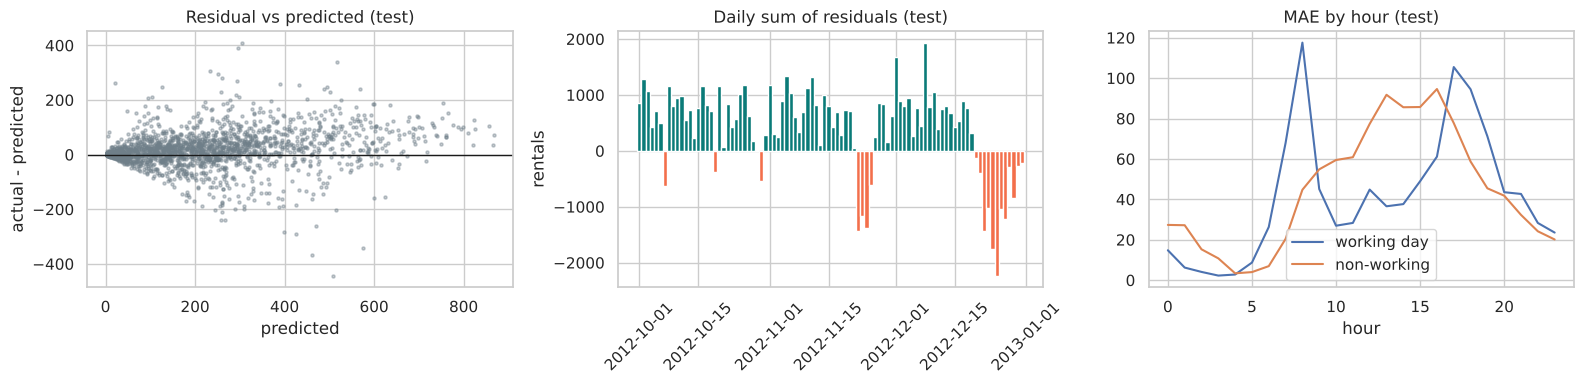

Spearman(|error|, predicted) = 0.623 -> error grows with level
Worst days by total error:


,sum of residuals
dteday,
2012-12-25,"-2,230.973"
2012-12-24,"-1,750.986"
2012-11-22,"-1,442.383"
2012-12-22,"-1,439.243"
2012-11-24,"-1,371.302"


,hours,MAE,mean_error (bias)
"working-day peaks 7-8, 17-18",242,96.383,40.432
all other hours,1926,35.688,13.415
rain/snow hours,160,63.987,26.446
holiday hours,95,71.894,-17.940
Hurricane Sandy 29-30 Oct,12,81.632,-43.849


,ts,workingday,weathersit,cnt,pred,error
17196,2012-12-24 08:00:00,1,1,66,508.921,-442.921
15252,2012-10-02 17:00:00,1,3,715,305.029,409.971
15253,2012-10-02 18:00:00,1,3,687,296.316,390.684
16454,2012-11-23 08:00:00,1,1,94,462.090,-368.090
15661,2012-10-19 18:00:00,1,1,233,574.304,-341.304
15228,2012-10-01 17:00:00,1,3,856,517.888,338.112
16819,2012-12-08 14:00:00,0,2,542,234.066,307.934
16818,2012-12-08 13:00:00,0,2,547,252.227,294.773


In [16]:
res = test[['ts', 'dteday', 'hr', 'workingday', 'holiday', 'weathersit', 'cnt']].copy()
res['pred'] = p_hgb; res['error'] = res['cnt'] - res['pred']; res['abs_error'] = res['error'].abs()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(res['pred'], res['error'], s=5, alpha=.4, color='#6F7F89'); ax[0].axhline(0, color='k', lw=1)
ax[0].set(title='Residual vs predicted (test)', xlabel='predicted', ylabel='actual - predicted')
dres = res.groupby('dteday')['error'].sum()
ax[1].bar(dres.index, dres.values, color=np.where(dres < 0, '#F36F4B', '#0A7B78'), width=1)
ax[1].set(title='Daily sum of residuals (test)', ylabel='rentals'); ax[1].tick_params(axis='x', rotation=45)
hres = res.groupby(['workingday', 'hr'])['abs_error'].mean().unstack(0)
ax[2].plot(hres.index, hres[1], label='working day'); ax[2].plot(hres.index, hres[0], label='non-working')
ax[2].set(title='MAE by hour (test)', xlabel='hour'); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / 'f5_residuals.png', dpi=150); plt.show()

print('Spearman(|error|, predicted) =', round(stats.spearmanr(res['abs_error'], res['pred'])[0], 3), '-> error grows with level')
print('Worst days by total error:'); display(dres.sort_values().head(5).to_frame('sum of residuals'))
peak = res['hr'].isin([7, 8, 17, 18]) & (res['workingday'] == 1)
groups = pd.DataFrame({
    'hours': [peak.sum(), (~peak).sum(), (res['weathersit'] == 3).sum(), res['holiday'].sum(),
              res['dteday'].isin(pd.to_datetime(['2012-10-29', '2012-10-30'])).sum()],
    'MAE': [res.loc[peak, 'abs_error'].mean(), res.loc[~peak, 'abs_error'].mean(),
            res.loc[res['weathersit'] == 3, 'abs_error'].mean(), res.loc[res['holiday'] == 1, 'abs_error'].mean(),
            res.loc[res['dteday'].isin(pd.to_datetime(['2012-10-29', '2012-10-30'])), 'abs_error'].mean()],
    'mean_error (bias)': [res.loc[peak, 'error'].mean(), res.loc[~peak, 'error'].mean(),
                          res.loc[res['weathersit'] == 3, 'error'].mean(), res.loc[res['holiday'] == 1, 'error'].mean(),
                          res.loc[res['dteday'].isin(pd.to_datetime(['2012-10-29', '2012-10-30'])), 'error'].mean()]},
    index=['working-day peaks 7-8, 17-18', 'all other hours', 'rain/snow hours', 'holiday hours', 'Hurricane Sandy 29-30 Oct'])
display(groups)
display(res.nlargest(8, 'abs_error')[['ts', 'workingday', 'weathersit', 'cnt', 'pred', 'error']])

**Error groups (test, gradient boosting).**
1. *Working-day peaks* (7-8, 17-18; 242 hours): MAE 96.4 against 35.7 in other hours. The bias is +40, so the model under-predicts the rush. This matters most: stations can run empty when demand is highest.
2. *Holiday-adjacent days:* the worst days are Dec 25 (-2,231), Dec 24, Nov 22 (Thanksgiving) and Nov 24. On Dec 24 at 8:00 the model expected 509 rentals and got 66, because Dec 24 is coded as a working day. Over-prediction here means staff and trucks are planned for demand that never comes.
3. *Rain hours and Sandy:* MAE 64.0 in rain or snow hours. During Hurricane Sandy MAE was 81.6 and the model over-predicted by 44 per hour. Sudden weather shocks are not in the lags.

Errors grow with the level of demand (Spearman 0.62 between absolute error and prediction), so the variance is not constant.

### Feature importance (permutation on the test period, model fixed)

In [17]:
pi = permutation_importance(hgb_final, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                            scoring='neg_mean_absolute_error')
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
display(imp.to_frame('MAE increase when shuffled').head(10))

,MAE increase when shuffled
hr_daytype,97.074
temp,20.163
lag168,12.506
lag24,9.077
hum,6.477
weathersit,5.102
weekday,2.858
hr,1.219
season,1.195
mnth,1.101


**Importance (permutation, test period).** If `hr_daytype` is shuffled, MAE rises by 97. For temperature it rises by 20, for `lag168` by 12.5 and for `lag24` by 9. The model leans mainly on the daily routine and temperature. This shows what the model uses for prediction, not what causes people to ride.

# Part 5. Clustering days by weather

**Object:** one day. **Purpose:** group days by forecastable weather so operators can pick a plan the evening before.
**Features (5):** mean temperature, max temperature, mean humidity, mean wind, hours of rain/snow (log1p). No `cnt`, `casual`, `registered`, no lags. Calendar is left out and used only for profiling. Fitted on the 547 training days, other days assigned.

In [18]:
day_feat = df.groupby('dteday').agg(temp_mean=('temp', 'mean'), temp_max=('temp', 'max'), hum_mean=('hum', 'mean'),
                                    wind_mean=('windspeed', 'mean'),
                                    rain_hours=('weathersit', lambda s: int((s == 3).sum())))
day_feat['log_rain_hours'] = np.log1p(day_feat['rain_hours'])
CF = ['temp_mean', 'temp_max', 'hum_mean', 'wind_mean', 'log_rain_hours']
tr_days = day_feat.index < '2012-07-01'
cprep = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
C_tr = cprep.fit_transform(day_feat.loc[tr_days, CF]); C_all = cprep.transform(day_feat[CF])

def boot_ari(k, B=20):
    ref = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(C_tr)
    rng = np.random.default_rng(RANDOM_STATE); out = []
    for b in range(B):
        idx = rng.choice(len(C_tr), len(C_tr), replace=True)
        out.append(adjusted_rand_score(ref.labels_, KMeans(k, n_init=20, random_state=b).fit(C_tr[idx]).predict(C_tr)))
    return np.mean(out), np.min(out)

rows = []
for k in range(2, 7):
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(C_tr)
    wd = AgglomerativeClustering(k, linkage='ward').fit_predict(C_tr)
    ba = boot_ari(k)
    rows.append({'k': k, 'kmeans_silhouette': silhouette_score(C_tr, km.labels_), 'kmeans_CH': calinski_harabasz_score(C_tr, km.labels_),
                 'kmeans_DB': davies_bouldin_score(C_tr, km.labels_), 'ward_silhouette': silhouette_score(C_tr, wd),
                 'ARI_kmeans_vs_ward': adjusted_rand_score(km.labels_, wd), 'bootstrap_ARI_mean': ba[0], 'bootstrap_ARI_min': ba[1],
                 'smallest': np.bincount(km.labels_).min()})
cl = pd.DataFrame(rows); display(cl)

,k,kmeans_silhouette,kmeans_CH,kmeans_DB,ward_silhouette,ARI_kmeans_vs_ward,bootstrap_ARI_mean,bootstrap_ARI_min,smallest
0,2,0.288,238.812,1.415,0.274,0.685,0.895,0.779,263
1,3,0.322,267.275,1.084,0.294,0.629,0.935,0.856,120
2,4,0.301,241.353,1.101,0.251,0.401,0.755,0.498,71
3,5,0.270,224.886,1.152,0.236,0.496,0.605,0.417,76
4,6,0.276,222.468,1.098,0.226,0.682,0.814,0.596,73


k = 3: 10 seeds (n_init=1) mean ARI = 0.996, min = 0.985


,days,temp_C,temp_max_C,hum_pct,wind_kmh,rain_hours
cluster,,,,,,
0,120,17.800,20.700,79.400,13.900,7.600
1,195,12.900,16.700,52.200,14.600,0.400
2,232,26.300,30.500,62.500,11.600,0.600


,"mean daily cnt, non-working","mean daily cnt, working"
cluster,,
0,"2,784.000","2,992.000"
1,"2,849.000","3,394.000"
2,"5,455.000","5,082.000"


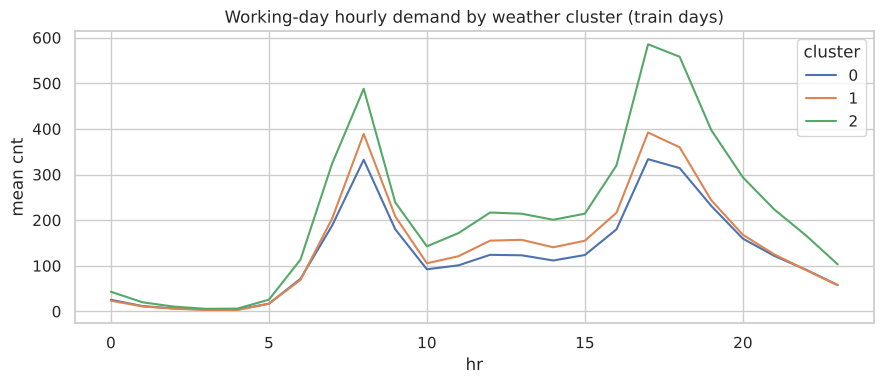

In [19]:
K = 3  # chosen from the table above
km = KMeans(K, n_init=20, random_state=RANDOM_STATE).fit(C_tr)
seed_ari = [adjusted_rand_score(km.labels_, KMeans(K, n_init=1, random_state=s).fit_predict(C_tr)) for s in range(10)]
print(f'k = {K}: 10 seeds (n_init=1) mean ARI = {np.mean(seed_ari):.3f}, min = {np.min(seed_ari):.3f}')

day_feat['cluster'] = km.predict(C_all)
orig = day_feat.assign(temp_C=day_feat['temp_mean'] * 41, temp_max_C=day_feat['temp_max'] * 41,
                       hum_pct=day_feat['hum_mean'] * 100, wind_kmh=day_feat['wind_mean'] * 67)
prof = orig[tr_days].groupby('cluster').agg(days=('temp_C', 'size'), temp_C=('temp_C', 'mean'), temp_max_C=('temp_max_C', 'mean'),
                                            hum_pct=('hum_pct', 'mean'), wind_kmh=('wind_kmh', 'mean'),
                                            rain_hours=('rain_hours', 'mean'))
display(prof.round(1))

# Usefulness, outcome used only after clustering
dd = daily.join(day_feat['cluster'])
use = dd[dd.index < '2012-07-01'].groupby(['cluster', 'workingday'])['cnt'].mean().unstack().round(0)
use.columns = ['mean daily cnt, non-working', 'mean daily cnt, working']
display(use)
hp = df[df['dteday'] < '2012-07-01'].merge(day_feat['cluster'], left_on='dteday', right_index=True)
hp = hp[hp['workingday'] == 1].groupby(['cluster', 'hr'])['cnt'].mean().unstack(0)
hp.plot(figsize=(9, 4), title='Working-day hourly demand by weather cluster (train days)'); plt.ylabel('mean cnt')
plt.tight_layout(); plt.savefig(FIG / 'f6_cluster_profiles.png', dpi=150); plt.show()

**Choice.** K-means with k = 3 is best on all three internal measures: silhouette 0.322, Calinski-Harabasz 267, Davies-Bouldin 1.08. It is also the most stable: bootstrap ARI 0.935 (min 0.856), and ten single-start seeds give ARI 0.996. Ward agrees at ARI 0.63, so the main split holds across methods. For k of 4 or more, stability falls (ARI 0.61 to 0.81).

| Cluster | Training days | Profile (means) | Name | Mean daily rentals, working / non-working |
|---|---|---|---|---|
| 0 | 120 | 17.8 C, humidity 79%, 7.6 rain hours | Humid rainy days | 2,992 / 2,784 |
| 1 | 195 | 12.9 C, humidity 52%, 0.4 rain hours | Cool dry days | 3,394 / 2,849 |
| 2 | 232 | 26.3 C, humidity 63%, 0.6 rain hours | Warm dry days | 5,082 / 5,455 |

**Operational meaning.** On warm dry days demand is 50% to 96% higher than on the other two types, and weekends beat working days (5,455 vs 5,082). Leisure riding matters here, so bikes should be moved to parks and the waterfront. On cool dry days commuting dominates, so the plan is to rebalance for the 8:00 and 17:00 peaks. Humid rainy days are low-demand days, which suits maintenance work. The day type can be set from the evening forecast.

*Limitation:* clusters use daily averages and observed weather, and they partly mirror the seasons. Rain that falls only at rush hour is diluted.

# Part 6. Time series (daily)

Days: 731 | missing days: 0 | days with < 20 recorded hours: 8


,model,partition,n,MAE,RMSE,R2
0,Seasonal naive (same weekday last week),test Oct-Dec 2012 (92 days),92,"1,457.587","2,047.168",-0.137
1,Holt-Winters (trend + weekly),test Oct-Dec 2012 (92 days),92,"2,948.659","3,588.538",-2.495
2,Ridge: trend + calendar + weather,test Oct-Dec 2012 (92 days),92,976.756,"1,486.004",0.401


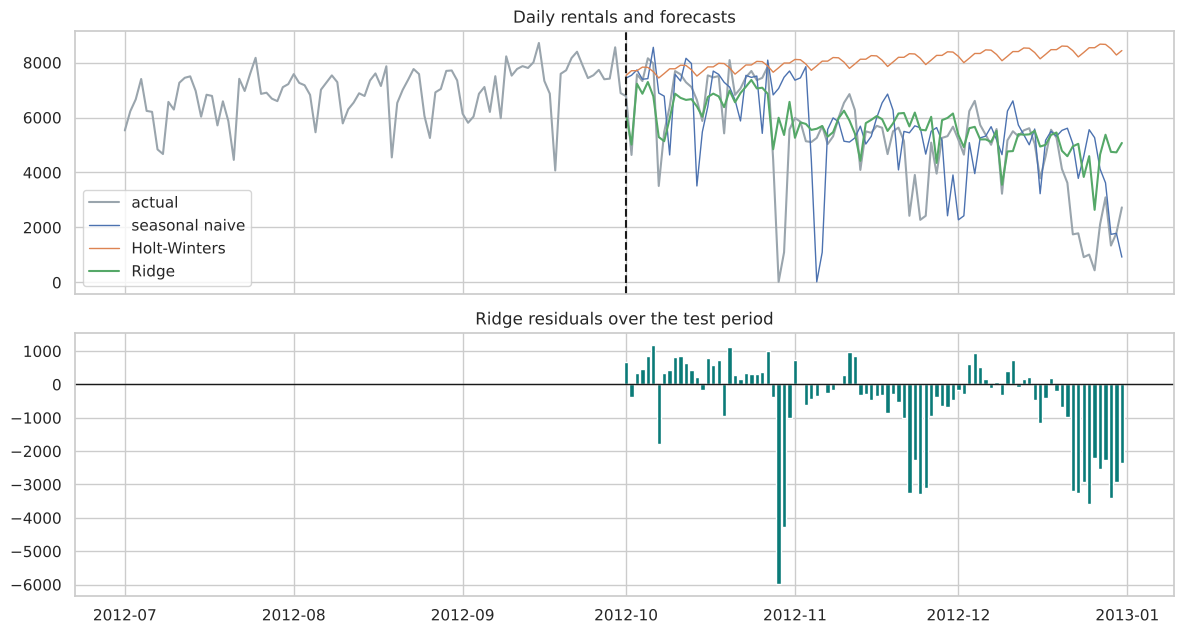

Monthly mean daily rentals:
dteday
2011-01   1,232.000
2011-02   1,722.000
2011-03   2,066.000
2011-04   3,162.000
2011-05   4,381.000
2011-06   4,784.000
2011-07   4,559.000
2011-08   4,409.000
2011-09   4,247.000
2011-10   3,984.000
2011-11   3,406.000
2011-12   2,817.000
2012-01   3,121.000
2012-02   3,556.000
2012-03   5,319.000
2012-04   5,807.000
2012-05   6,318.000
2012-06   6,761.000
2012-07   6,568.000
2012-08   6,919.000
2012-09   7,286.000
2012-10   6,414.000
2012-11   5,089.000
2012-12   3,991.000
Freq: M


In [20]:
ts = daily['cnt'].asfreq('D')
print('Days:', len(ts), '| missing days:', int(ts.isna().sum()), '| days with < 20 recorded hours:', int((daily['hours'] < 20).sum()))
ts_tr, ts_te = ts[:'2012-09-30'], ts['2012-10-01':]
naive = ts.shift(7)['2012-10-01':]

hw = ExponentialSmoothing(ts_tr, trend='add', seasonal='add', seasonal_periods=7).fit()
hw_fc = hw.forecast(len(ts_te))

D = daily.copy(); D['t'] = np.arange(len(D))
DF = ['t', 'temp', 'hum', 'windspeed', 'bad_hours', 'workingday', 'holiday']
DC = ['mnth', 'weekday']
dprep = ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), DC),
                           ('n', Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]), DF)])
dreg = Pipeline([('p', dprep), ('m', Ridge(alpha=1.0))]).fit(D.loc[:'2012-09-30', DF + DC], D.loc[:'2012-09-30', 'cnt'])
reg_fc = pd.Series(dreg.predict(D.loc['2012-10-01':, DF + DC]), index=ts_te.index)

tsm = pd.DataFrame([reg_metrics('Seasonal naive (same weekday last week)', 'test Oct-Dec 2012 (92 days)', ts_te, naive),
                    reg_metrics('Holt-Winters (trend + weekly)', 'test Oct-Dec 2012 (92 days)', ts_te, hw_fc),
                    reg_metrics('Ridge: trend + calendar + weather', 'test Oct-Dec 2012 (92 days)', ts_te, reg_fc)])
display(tsm)

fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(ts['2012-07-01':], color='#9AA5AD', label='actual')
ax[0].plot(naive, label='seasonal naive', lw=1); ax[0].plot(hw_fc, label='Holt-Winters', lw=1); ax[0].plot(reg_fc, label='Ridge', lw=1.5)
ax[0].axvline(pd.Timestamp('2012-10-01'), color='k', ls='--'); ax[0].legend(); ax[0].set_title('Daily rentals and forecasts')
ax[1].bar(ts_te.index, ts_te - reg_fc, color='#0A7B78'); ax[1].axhline(0, color='k', lw=1); ax[1].set_title('Ridge residuals over the test period')
plt.tight_layout(); plt.savefig(FIG / 'f7_timeseries.png', dpi=150); plt.show()
m = (ts.groupby(ts.index.to_period('M')).mean()).round(0)
print('Monthly mean daily rentals:'); print(m.to_string())

**Setup.** I aggregated to days, which removes the nightly zeros and the hour gaps. There are no missing days, but 8 days have fewer than 20 recorded hours (Sandy, the January 2011 storm). Train runs to 2012-09-30 and the test covers the last 92 days.

**Result.** The seasonal naive rule (same weekday last week) gives MAE 1,458 and R2 -0.14. Holt-Winters with trend and weekly seasonality is worse (MAE 2,949, R2 -2.50). It extends the 2012 growth into autumn, when demand actually fell from 7,286 to 3,991 per day. Ridge with trend, month, weekday and weather reaches MAE 977, RMSE 1,486 and R2 0.40, about 33% below the naive rule.

**Residuals.** The largest misses are Sandy (Oct 29: -5,971; Oct 30: -4,269), Christmas (Dec 25: -3,582) and the weekend after Thanksgiving. The mean residual is -538, so the model over-predicts the end of 2012. Growth slowed, and the trend term did not see it.

*Limitation:* two years give only two seasonal cycles. Yearly seasonality and trend are confounded, so the trend estimate is weak.

# Part 7. Recommendation, NLP and advanced methods

In [21]:
text_cols = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype) in ('str', 'string')]
print('Non-numeric columns:', text_cols, '-> dates only, no free text')

Xm_tr, Xm_val, Xm_test = X_tr, X_val, X_test
mlp_scores = []
for h in [(32,), (64, 32)]:
    mlp = TransformedTargetRegressor(Pipeline([('prep', linear_prep()),
          ('m', MLPRegressor(hidden_layer_sizes=h, alpha=1e-3, learning_rate_init=1e-3, max_iter=300,
                             early_stopping=True, validation_fraction=0.1, n_iter_no_change=15, random_state=RANDOM_STATE))]),
          func=np.log1p, inverse_func=np.expm1).fit(Xm_tr, y_tr)
    mlp_scores.append(reg_metrics(f'MLP {h}', 'validation', y_val, mlp.predict(Xm_val)))
best_h = [(32,), (64, 32)][int(np.argmin([r['RMSE'] for r in mlp_scores]))]
mlp_final = TransformedTargetRegressor(Pipeline([('prep', linear_prep()),
          ('m', MLPRegressor(hidden_layer_sizes=best_h, alpha=1e-3, learning_rate_init=1e-3, max_iter=300,
                             early_stopping=True, validation_fraction=0.1, n_iter_no_change=15, random_state=RANDOM_STATE))]),
          func=np.log1p, inverse_func=np.expm1).fit(X_dev, y_dev)
display(pd.DataFrame(mlp_scores + [reg_metrics(f'MLP {best_h}', 'test Oct-Dec 2012', y_test, mlp_final.predict(X_test)),
                                   final.iloc[2].to_dict()]))

Non-numeric columns: [] -> dates only, no free text


,model,partition,n,MAE,RMSE,R2
0,"MLP (32,)",validation,2208,41.726,66.545,0.917
1,"MLP (64, 32)",validation,2208,43.683,68.080,0.913
2,"MLP (32,)",test Oct-Dec 2012,2168,47.255,74.614,0.863
3,Gradient boosting (Poisson),test Oct-Dec 2012,2168,42.463,66.323,0.892


**Recommendation.** The file has no users, stations or trips, only hourly totals. A valid formulation would be station-to-station recommendations ("users who start at station A often end at B") or suggesting a nearby station with free bikes. That needs trip-level data with user or card id, start and end station and time. Without interactions there is nothing to hold out, so an honest offline evaluation (hit rate or recall@k on a later period) cannot be done.

**NLP.** There is no free text. All columns are numeric codes or dates. Turning labels such as "season = 2" or "weathersit = 3" into words and running TF-IDF would only re-encode one-hot variables, so it is not NLP.

**MLP.** I tested it. The hourly table is large enough (13,003 training hours) and the effects are non-linear. A one-layer MLP (32 units) was slightly better than gradient boosting on validation (RMSE 66.5 vs 67.8), but worse on the test quarter (MAE 47.3 vs 42.5; RMSE 74.6 vs 66.3). Gradient boosting stays the final model: it generalised better across the period change, is easier to explain, and trains in seconds.

**CNN.** A CNN needs images or a grid, for example satellite or weather-radar images matched to hours, or a station-by-time demand map. This file has one city-wide number per hour, so it does not support a CNN.

**RAG and transformers.** Use: explain unusual demand days. Documents: city event calendars, weather service reports and Capital Bikeshare service notices for 2011 to 2012. Query: "Why were rentals near zero on 2012-10-29?" Expected answer: Hurricane Sandy closed the city and the system, with a citation to the source page. Unsupported output is caught by requiring a retrieved passage for every claim, checking that the cited date matches the query date, and rejecting answers with no source.

# Part 8. Conclusions and claim audit

**Three conclusions.**
1. Day-ahead hourly demand can be predicted well beyond a simple rule. On Oct to Dec 2012 (2,168 hours), gradient boosting reached MAE 42.5 and R2 0.892, against MAE 71.3 for "same hour last week" (40% lower; Part 4 table).
2. Working days change when people ride, not how much. 58.6% of rentals fall in commute hours on working days, against 34.5% on other days (r = 0.99), while daily totals differ by only 3% (p = 0.12; Part 2 tests).
3. Days fall into three stable weather types (bootstrap ARI 0.94). Warm dry days have 50% to 96% more rentals than the other two types, depending on day type (Part 5 tables).

**Main limitation.** Weather is the observed value, not a forecast, so real day-ahead accuracy will be lower than reported.

**Recommendation.** Plan rebalancing from the model's day-ahead forecast, add a safety margin at the 8:00 and 17:00 peaks, which are under-predicted by about 40 rentals per hour, and treat holiday-adjacent days by hand.

**Next analysis needing more data.** Station-level trip records plus archived weather forecasts. With them I could predict empty and full stations, which is the real operational problem.

**Claim audit.**
*Claim:* "Warm weather causes people to rent more bikes; each degree adds the same number of rentals."
*Label:* overstated.
*Evidence:* Spearman rho is 0.62 (Part 2, Test 2), but Figure 3 shows the curve flattens above 30 C and falls above 38 C, and the design is observational.
*Corrected:* "Daily rentals are strongly associated with temperature (Spearman rho = 0.62). The relationship rises up to about 30 to 34 C and declines in the hottest hours, and it is not a causal estimate."